## 1. Conexión a la fuente de datos

In [15]:
import sys
from pathlib import Path
from configparser import ConfigParser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Agregar src al path para importar módulos
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / 'src'))

from db.connection import PostgresConnection

In [16]:
# Configurar ruta al archivo de configuración
config_path = project_root / 'configs' / 'database.ini'

# Leer configuración INI
config = ConfigParser()
config.read(config_path)

# Crear conexión con parámetros del INI
pg_conn = PostgresConnection(
    host=config.get('postgres', 'host'),
    port=config.getint('postgres', 'port'),
    dbname=config.get('postgres', 'dbname'),
    user=config.get('postgres', 'user'),
    password=config.get('postgres', 'password')
)
conn = pg_conn.connect()

print(f"✓ Conexión establecida exitosamente")
print(f"Base de datos: {pg_conn.dbname}")
print(f"Host: {pg_conn.host}:{pg_conn.port}")

✓ Conexión establecida exitosamente
Base de datos: postgres
Host: localhost:5432


In [17]:
# Leer tabla completa usando pandas
query = "SELECT * FROM r$_ds_obras_publicas_infobras"

df = pd.read_sql(query, conn)

print(f"Registros cargados: {len(df):,}")
print(f"Columnas: {len(df.columns)}")

C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\1384694517.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


Registros cargados: 69,952
Columnas: 128


In [18]:
df['colegiatura_2'].count()

np.int64(63805)

In [19]:
df.groupby(df['modalidad_ejecucion_obra']).count()

,codigo_entidad,entidad_publica,codigo_infobras,nombre_obra,flg_corresponde_saldo_obra,codigo_infobras_obra_inicial,naturaleza_obra,tipo_obra_nivel_1,tipo_obra_nivel_2,tipo_obra_nivel_3,...,inv_monto_viable,fuente_financiamiento,tasa_paralizacion_entidad,n_obras_x_entidad,inv_monto_viable_promedio_entidad,tasa_paralizacion_departamento,tasa_paralizacion_distrito,tasa_paralizacion_tipo_obra_nivel_1,causal_paralizacion_2,flg_opa_incumplimiento_contractual
modalidad_ejecucion_obra,,,,,,,,,,,,,,,,,,,,,
Contrata,69948,69948,69952,69952,69952,669,69952,69952,69952,69952,...,69572,39824,69948,69948,69947,69920,69920,69952,1763,69952


In [21]:
# Columnas del DataFrame
print("Columnas disponibles:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2}. {col}")

Columnas disponibles:
 1. codigo_entidad
 2. entidad_publica
 3. codigo_infobras
 4. nombre_obra
 5. modalidad_ejecucion_obra
 6. flg_corresponde_saldo_obra
 7. codigo_infobras_obra_inicial
 8. naturaleza_obra
 9. tipo_obra_nivel_1
10. tipo_obra_nivel_2
11. tipo_obra_nivel_3
12. estado_ejecucion
13. flg_reconstruccion_con_cambios
14. flg_reactivacion_economica
15. otra_marca
16. n_informes_monitores_ciudadanos
17. n_denuncias_viculadas
18. n_informes_control
19. n_comentarios_ciudadanos
20. flg_obra_caracter_reservado
21. nivel_gobierno
22. sector_entidad
23. codigo_unico
24. codigo_snip
25. nombre_proyecto
26. estado_proyecto
27. tipo_formato
28. monto_viable_aprobado
29. fecha_aprobacion
30. monto_viable_actualizado
31. fecha_actualizacion
32. n_obras_relacionadas_proyecto
33. departamento
34. provincia
35. distrito
36. direccion_informacion_referencia
37. tipo_ubicacion
38. fecha_aprobacion_expediente
39. monto_aprobacion_et
40. moneda
41. tasa_cambio
42. monto_aprobado_soles
43. do

## Analisis exploratorio de datos (EDA)

C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\2316806541.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)
C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\2316806541.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)
C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\2316806541.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)
C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\2316806541.py:66: UserWarning: set_tickla

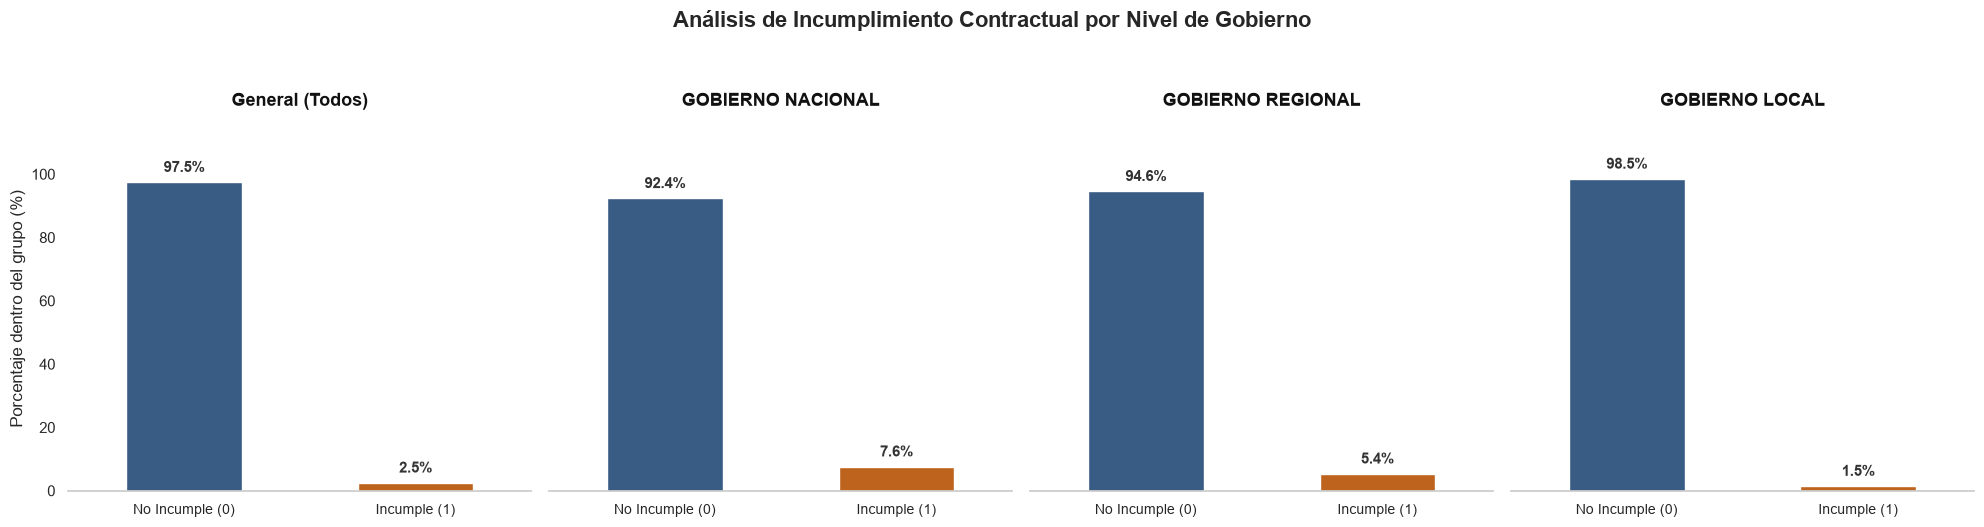

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- 1. PREPARACIÓN DE DATOS ---
# Gráfico General (Total)
df_general = df['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).reset_index()
df_general.columns = ['Clase', 'Porcentaje']
df_general['Grupo'] = 'General (Todos)'

# Gráficos por Nivel de Gobierno (Normalizado por cada nivel)
df_niveles = df.groupby('nivel_gobierno')['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).reset_index()
df_niveles.columns = ['Grupo', 'Clase', 'Porcentaje']

# Unimos ambos análisis en un solo DataFrame estructurado
df_final = pd.concat([df_general, df_niveles], ignore_index=True)
df_final['Porcentaje'] = df_final['Porcentaje'] * 100  # Convertir a base 100

# --- 2. CONFIGURACIÓN DEL LIENZO (1 fila, 4 columnas) ---
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Paleta de colores consistente (Azul para 0, Naranja para 1)
colors = {0: '#2b5c8f', 1: '#d95f02'}
orden_grupos = ['General (Todos)', 'GOBIERNO NACIONAL', 'GOBIERNO REGIONAL', 'GOBIERNO LOCAL']

# --- 3. BUCLE PARA GENERAR CADA GRÁFICO ---
for i, grupo in enumerate(orden_grupos):
    ax = axes[i]
    # Filtramos los datos correspondientes a este subgráfico
    df_sub = df_final[df_final['Grupo'] == grupo]
    
    # Dibujamos las barras
    bars = sns.barplot(
        x='Clase', 
        y='Porcentaje', 
        data=df_sub, 
        palette=colors, 
        hue='Clase', 
        legend=False,
        width=0.5,
        ax=ax
    )
    
    # Añadimos las etiquetas de porcentaje sobre cada barra
    for bar in bars.patches:
        height = bar.get_height()
        if height > 0: # Evita etiquetar si alguna clase tiene 0%
            ax.annotate(
                f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom', 
                fontsize=11, fontweight='bold', color='#333333'
            )
            
    # Estética del subgráfico (Limpieza visual)
    ax.set_title(f'{grupo}', fontsize=13, fontweight='bold', pad=15, color='#111111')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc')
    ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)

# Ajustes globales del lienzo
axes[0].set_ylabel('Porcentaje dentro del grupo (%)', fontsize=12, fontweight='medium')
plt.ylim(0, 115) # Espacio para que las etiquetas no se corten
plt.suptitle('Análisis de Incumplimiento Contractual por Nivel de Gobierno', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


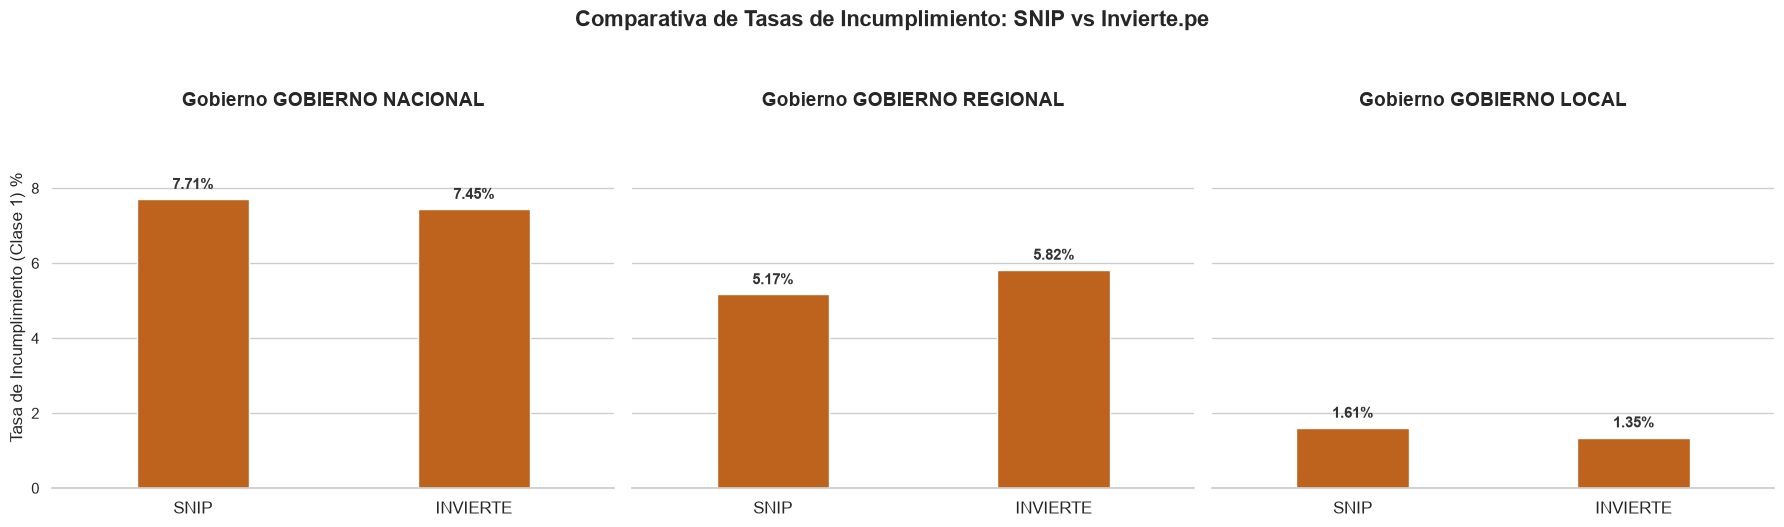

In [ ]:
# --- 1. PREPARACIÓN DE DATOS (Calcular tasas de incumplimiento) ---
# Agrupamos por Nivel de Gobierno y Marco para calcular el % de cada clase
df_counts = df.groupby(['nivel_gobierno', 'marco'])['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).reset_index()
df_counts.columns = ['Nivel_gobierno', 'Marco', 'Clase', 'Proporcion']
df_counts['Porcentaje'] = df_counts['Proporcion'] * 100

# Filtramos ÚNICAMENTE la Clase 1 (Incumplimiento) para que el gráfico sea legible y útil
df_incumplimiento = df_counts[df_counts['Clase'] == 1]

# --- 2. CONFIGURACIÓN DEL LIENZO (1 fila, 3 columnas) ---
sns.set_theme(style="whitegrid") # Cuadrícula sutil de fondo para comparar alturas fácilmente
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

niveles = ['GOBIERNO NACIONAL', 'GOBIERNO REGIONAL', 'GOBIERNO LOCAL']
# Color naranja corporativo para resaltar el riesgo de incumplimiento
color_incumple = '#d95f02' 

# --- 3. BUCLE PARA GENERAR CADA PANEL ---
for i, nivel in enumerate(niveles):
    ax = axes[i]
    # Filtrar datos del nivel actual
    df_sub = df_incumplimiento[df_incumplimiento['Nivel_gobierno'] == nivel]
    
    # Dibujar barras comparando SNIP vs Invierte
    bars = sns.barplot(
        x='Marco', 
        y='Porcentaje', 
        data=df_sub, 
        color=color_incumple,
        order=['SNIP', 'INVIERTE'],
        width=0.4,
        ax=ax
    )
    
    # Añadir etiquetas de porcentaje exacto sobre las barras
    for bar in bars.patches:
        height = bar.get_height()
        ax.annotate(
            f'{height:.2f}%', # Dos decimales por ser porcentajes pequeños
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha='center', va='bottom', 
            fontsize=11, fontweight='bold', color='#333333'
        )
        
    # Estética de cada panel
    ax.set_title(f'Gobierno {nivel}', fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='x', labelsize=12)

# --- 4. DETALLES FINALES DEL GRÁFICO MULTIPANEL ---
axes[0].set_ylabel('Tasa de Incumplimiento (Clase 1) %', fontsize=12, fontweight='medium')

# Ajustar el límite superior dinámicamente con un margen para las etiquetas
max_y = df_incumplimiento['Porcentaje'].max()
plt.ylim(0, max_y * 1.25)

plt.suptitle('Comparativa de Tasas de Incumplimiento: SNIP vs Invierte.pe', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


C:\Users\yanfr\AppData\Local\Temp\ipykernel_42144\1689428358.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels, fontsize=12, fontweight='medium')


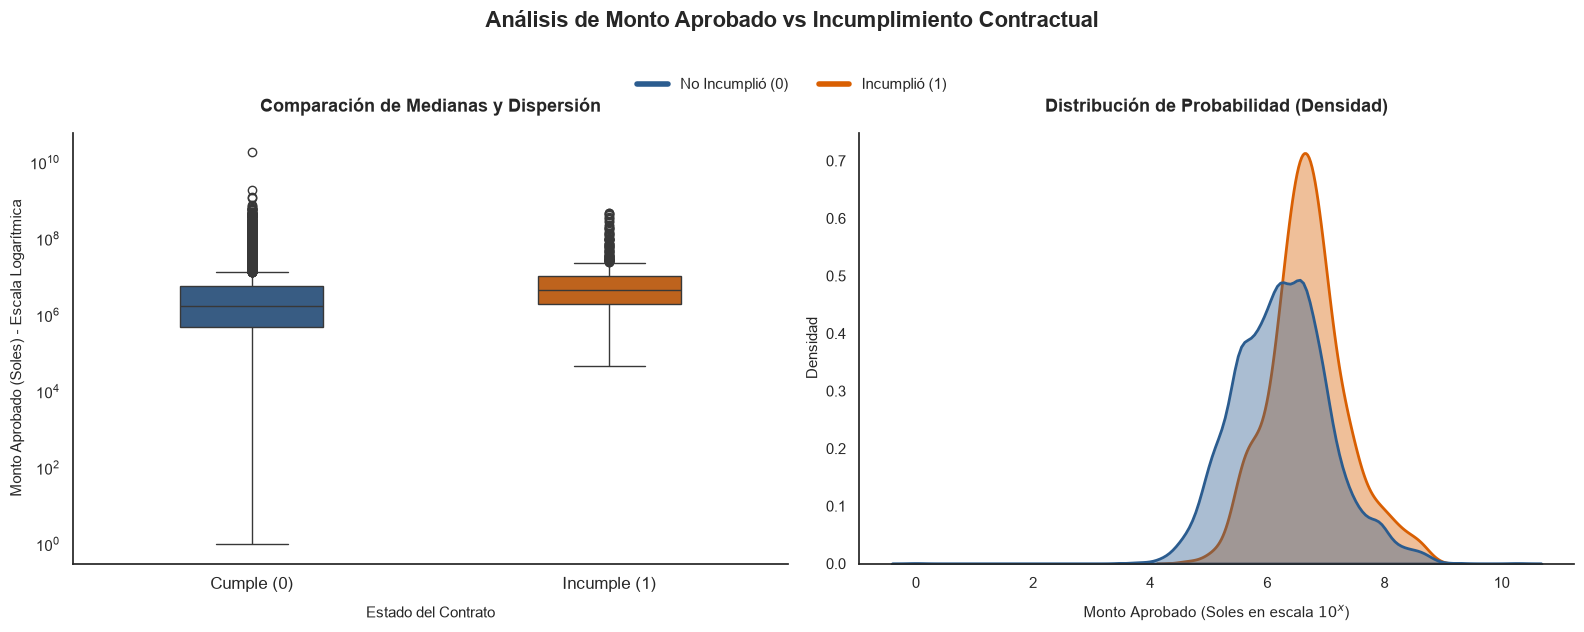

--- RESUMEN ESTADÍSTICO POR CLASE ---
                  count        median           mean             std
Cumple (0)    67,993.00    867,813.38   4,962,345.82  115,810,943.66
Incumple (1)   1,763.00  4,083,987.11  15,005,810.81   43,178,426.73


In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- 1. CONFIGURACIÓN DEL LIENZO (1 fila, 2 columnas) ---
sns.set_theme(style="white")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Paleta de colores consistente (Azul para Cumple, Naranja para Incumple)
colors = {0: '#2b5c8f', 1: '#d95f02'}
labels = ['Cumple (0)', 'Incumple (1)']

# --- 2. GRÁFICO 1: BOXPLOT CON ESCALA LOGARÍTMICA ---
# Evitamos problemas con montos de 0 o negativos aplicando log10 solo a valores mayores a 0
df_pos = df[(df['monto_aprobado_soles'] > 0) & (df['nivel_gobierno'] == "GOBIERNO NACIONAL")].copy()

sns.boxplot(
    x='flg_opa_incumplimiento_contractual',
    y='monto_aprobado_soles',
    data=df_pos,
    palette=colors,
    hue='flg_opa_incumplimiento_contractual',
    legend=False,
    width=0.4,
    ax=ax1
)

# Transformamos el eje Y a escala logarítmica para manejar la enorme disparidad de montos
ax1.set_yscale('log')
ax1.set_xticklabels(labels, fontsize=12, fontweight='medium')
ax1.set_xlabel('Estado del Contrato', fontsize=11, labelpad=10)
ax1.set_ylabel('Monto Aprobado (Soles) - Escala Logarítmica', fontsize=11)
ax1.set_title('Comparación de Medianas y Dispersión', fontsize=13, fontweight='bold', pad=15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 3. GRÁFICO 2: DENSIDAD (KDE) SUPERPUESTA ---
# Graficamos el logaritmo del monto para estabilizar la visualización de la densidad
df_pos['log_monto'] = np.log10(df_pos['monto_aprobado_soles'])

sns.kdeplot(
    data=df_pos,
    x='log_monto',
    hue='flg_opa_incumplimiento_contractual',
    palette=colors,
    fill=True,
    common_norm=False, # IMPORTANTE: Normaliza cada clase de forma independiente por el desbalance
    alpha=0.4,
    linewidth=2,
    ax=ax2
)

# Formatear el eje X para que muestre los valores reales en lugar del exponente puro
ax2.set_title('Distribución de Probabilidad (Densidad)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Monto Aprobado (Soles en escala $10^x$)', fontsize=11, labelpad=10)
ax2.set_ylabel('Densidad', fontsize=11)
ax2.get_legend().remove() # Removemos leyenda por defecto de seaborn para personalizarla
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Añadir una leyenda única y limpia arriba
fig.legend(
    handles=[
        plt.Line2D([0], [0], color='#2b5c8f', lw=4, label='No Incumplió (0)'),
        plt.Line2D([0], [0], color='#d95f02', lw=4, label='Incumplió (1)')
    ],
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.96), 
    ncol=2, 
    fontsize=11,
    frameon=False
)

plt.suptitle('Análisis de Monto Aprobado vs Incumplimiento Contractual', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# --- 4. ESTADÍSTICAS COMPLEMENTARIAS (Consola) ---
print("--- RESUMEN ESTADÍSTICO POR CLASE ---")
resumen = df.groupby('flg_opa_incumplimiento_contractual')['monto_aprobado_soles'].agg(['count', 'median', 'mean', 'std'])
resumen.index = labels
print(resumen.map(lambda x: f"{x:,.2f}" if x > 10 else f"{int(x)}"))

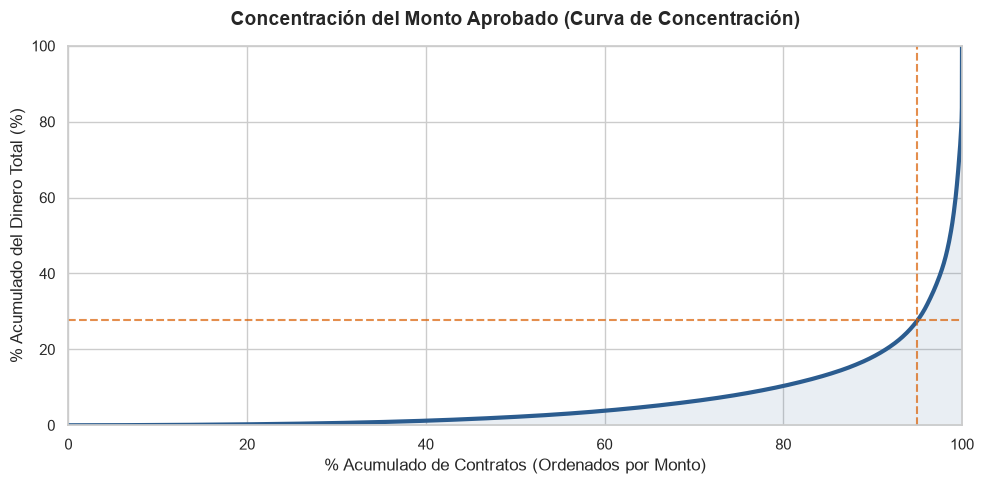

El 5% de los proyectos más grandes concentra el 72.4% de todo el dinero aprobado.


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ordenar los montos de menor a mayor
montos_ordenados = np.sort(df_pos['monto_aprobado_soles'].dropna())
monto_acumulado = np.cumsum(montos_ordenados) / np.sum(montos_ordenados) * 100
porcentaje_datos = np.arange(1, len(montos_ordenados) + 1) / len(montos_ordenados) * 100

# Gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(porcentaje_datos, monto_acumulado, color='#2b5c8f', linewidth=3)
ax.fill_between(porcentaje_datos, monto_acumulado, color='#2b5c8f', alpha=0.1)

# Encontrar el punto donde está el 95% de los datos
idx_95 = (porcentaje_datos >= 95).argmax()
monto_en_95 = monto_acumulado[idx_95]

# Líneas guía de Pareto
ax.axvline(x=95, color='#d95f02', linestyle='--', alpha=0.7)
ax.axhline(y=monto_en_95, color='#d95f02', linestyle='--', alpha=0.7)

ax.set_title('Concentración del Monto Aprobado (Curva de Concentración)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('% Acumulado de Contratos (Ordenados por Monto)', fontsize=12)
ax.set_ylabel('% Acumulado del Dinero Total (%)', fontsize=12)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

print(f"El 5% de los proyectos más grandes concentra el {100 - monto_en_95:.1f}% de todo el dinero aprobado.")


In [54]:
import pandas as pd
import numpy as np

# Calculamos los cuartiles de la variable
Q1 = df['monto_aprobado_soles'].quantile(0.25)
Q3 = df['monto_aprobado_soles'].quantile(0.75)
IQR = Q3 - Q1

# Definimos los límites estadísticos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 * 1.5 * IQR  # En finanzas se suele usar solo el límite superior

# Identificamos las filas atípicas
outliers_mask = df['monto_aprobado_soles'] > limite_superior
df_outliers = df[outliers_mask]

print(f"--- REPORTE DE OUTLIERS (MÉTODO IQR) ---")
print(f"Límite estadístico superior: S/. {limite_superior:,.2f}")
print(f"Cantidad de registros atípicos: {df_outliers.shape[0]:,}")
print(f"Porcentaje del dataset: {(df_outliers.shape[0] / df.shape[0]) * 100:.2f}%")


--- REPORTE DE OUTLIERS (MÉTODO IQR) ---
Límite estadístico superior: S/. 9,910,851,355,346.55
Cantidad de registros atípicos: 0
Porcentaje del dataset: 0.00%


In [55]:
# Creamos una columna temporal para segmentar el dataset
df['es_outlier'] = np.where(df['monto_aprobado_soles'] > limite_superior, 'Atípico (Monto Alto)', 'Normal')

# Cruzamos contra la variable objetivo
cruze_outliers = df.groupby('es_outlier')['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).unstack() * 100
cruze_outliers.columns = ['% Cumple (0)', '% Incumple (1)']
cruze_outliers['Cantidad_Total_Proyectos'] = df['es_outlier'].value_counts()

print("\n--- COMPORTAMIENTO DEL RIESGO SEGÚN EL MONTO ---")
print(cruze_outliers.round(2))



--- COMPORTAMIENTO DEL RIESGO SEGÚN EL MONTO ---
            % Cumple (0)  % Incumple (1)  Cantidad_Total_Proyectos
es_outlier                                                        
Normal             97.48            2.52                     69952


### Cerrar conexión a la base de datos

In [2]:
# =============================================================================
# Cerrar conexión a la base de datos
# =============================================================================

if pg_conn:
    pg_conn.close()
    print("✓ Conexión a PostgreSQL cerrada")

NameError: name 'pg_conn' is not defined